# Data 620 Week 7 Assignment - Project 2
### Author: Pedro P Gatica Jr

## Introduction: 
### These are the requirements for this project.

#### Identify a large 2-node network dataset—you can start with a dataset in a repository. Your data should meet the criteria that it consists of ties between and not within two (or more) distinct groups.
#### Reduce the size of the network using a method such as the island method described in chapter 4 of social network analysis.
#### What can you infer about each of the distinct groups?

### Source:
#### MovieLens 100K, 
##### A movie-ratings dataset collected by GroupLens Research at the University of Minnesota through the MovieLens website between September 1997 and April 1998. It contains 100,000 ratings (1-5 stars) from 943 users on 1,682 movies, and each user rated at least 20 movies. The data are a two-mode (bipartite) network: ties run only between users and movies, never user-to-user or movie-to-movie. This project keeps only ratings of 4 or higher, so a tie means that a user liked a movie.

### Citation (APA 7)
#### Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context. ACM Transactions on Interactive Intelligent Systems, 5(4), Article 19, 1-19. https://doi.org/10.1145/2827872

In [1]:
import argparse
import os
import numpy as np
import pandas as pd
# import matplotlib
# matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
from scipy import sparse
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from matplotlib.ticker import MaxNLocator

In [2]:
def project(A):
    """One-mode projection; edge weight = number of shared neighbours."""
    W = (A @ A.T).tocsr()
    W.setdiag(0)
    W.eliminate_zeros()
    return W

In [3]:
def find_islands(W, min_size=3, max_size=30, n_thresh=150):
    """Maximal connected components of {edges >= t} whose size is in range.
    Every edge leaving such a component is < t <= every edge inside its
    spanning tree, so each is an island in Batagelj's sense.
    Also returns the threshold sweep (t, #in-range components) for plotting."""
    ts = np.unique(np.quantile(W.data, np.linspace(0, 0.9995, n_thresh)))
    kept, sweep = [], []
    for t in ts:                      # ascending: larger islands found first
        M = W.copy()
        M.data[M.data < t] = 0
        M.eliminate_zeros()
        _, lab = connected_components(M, directed=False)
        sizes = np.bincount(lab)
        ok = np.where((sizes >= min_size) & (sizes <= max_size))[0]
        sweep.append((t, len(ok)))
        for c in ok:
            members = frozenset(np.where(lab == c)[0].tolist())
            if not any(members <= k for k in kept):
                kept.append(members)
    return [sorted(k) for k in kept], np.array(sweep)

In [4]:
def profile(A_side, islands, labels, top=5):
    base = np.asarray(A_side.mean(axis=0)).ravel()
    rows = []
    for i, members in enumerate(islands):
        share = np.asarray(A_side[members].mean(axis=0)).ravel()
        best = np.argsort(-(share - base))[:top]
        rows.append((i, len(members), [(labels[j], round(share[j], 2), round(base[j], 2)) for j in best]))
    return rows

In [5]:
def plot_degrees(A, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for a, deg, lab in [(ax[0], np.asarray(A.sum(axis=1)).ravel(), "movies liked per user"),
                        (ax[1], np.asarray(A.sum(axis=0)).ravel(), "users who liked each movie")]:
        a.hist(deg, bins=40, color="#4C72B0")
        a.set_yscale("log")
        a.set_xlabel(lab); a.set_ylabel("count (log)")
        a.set_title(f"median {np.median(deg):.0f}, max {deg.max():.0f}")
    fig.suptitle("1. Degree distributions of the 'liked' network")

In [6]:
def plot_reduction(before, after, outdir):
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.8))
    for a, name, b, f in zip(ax, ["Users", "Movies", "Ties"], before, after):
        bars = a.bar(["before", "after"], [b, f], color=["#999999", "#C44E52"])
        a.set_title(name)
        a.bar_label(bars, labels=[f"{b:,}", f"{f:,} ({f / b:.0%})"])
        a.set_ylim(0, b * 1.15)
    fig.suptitle("2. Reduction by the island method")

In [7]:
def plot_island_sizes(U_isl, M_isl, outdir, few=10):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

    for a, isl, name in [(ax[0], U_isl, "User islands"),
                         (ax[1], M_isl, "Movie islands")]:
        sizes = sorted((len(g) for g in isl), reverse=True)
        a.set_title(f"{name} (n={len(sizes)})")
        a.spines[["top", "right"]].set_visible(False)

        if not sizes:
            a.text(0.5, 0.5, "no islands", ha="center", va="center",
                   transform=a.transAxes)
            continue

        if len(sizes) <= few:
            # Few islands: show each one's size directly
            bars = a.bar(range(len(sizes)), sizes, color="#55A868")
            a.bar_label(bars, padding=2)
            a.set_xticks(range(len(sizes)))
            a.set_xticklabels([f"#{i+1}" for i in range(len(sizes))])
            a.set_xlabel("island (largest first)")
            a.set_ylabel("island size")
            a.set_ylim(0, max(sizes) * 1.15)
        else:
            # Many islands: histogram with data-driven, log-spaced bins
            bins = np.geomspace(min(sizes), max(sizes) + 1, 20)
            a.hist(sizes, bins=bins, color="#55A868")
            a.set_xscale("log")
            a.set_xlabel("island size (log scale)")
            a.set_ylabel("number of islands")
            a.yaxis.set_major_locator(MaxNLocator(integer=True))

    fig.suptitle("3. Island size distributions")

In [8]:
def plot_sweep(sw_u, sw_m, outdir):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for a, sw, name in [(ax[0], sw_u, "User projection"), (ax[1], sw_m, "Movie projection")]:
        a.plot(sw[:, 0], sw[:, 1], color="#8172B2")
        a.set_title(name); a.set_xlabel("weight threshold (shared neighbours)")
        a.set_ylabel("components within size range")
    fig.suptitle("4. Threshold sweep")

In [9]:
def island_sweep(W, min_size=3, max_size=30, n_thresh=400):
    """For each threshold t: # components with size in range, and largest component size."""
    W = W.tocsr()
    ts = np.unique(np.quantile(W.data, np.linspace(0, 0.9999, n_thresh)))
    rows = []
    for t in ts:
        M = W.copy()
        M.data[M.data < t] = 0
        M.eliminate_zeros()
        _, lab = connected_components(M, directed=False)
        sizes = np.bincount(lab)
        rows.append((t,
                     int(((sizes >= min_size) & (sizes <= max_size)).sum()),
                     int(sizes.max())))
    return pd.DataFrame(rows, columns=["threshold", "in_range", "largest"])

In [10]:
def plot_network(sub, u_island, m_island, outdir):
    """Reduced bipartite graph. Circles = users, squares = movies,
    colour = island."""
    G = nx.Graph()
    ui, mi = sub.nonzero()
    G.add_nodes_from([("u", i) for i in range(sub.shape[0])])
    G.add_nodes_from([("m", j) for j in range(sub.shape[1])])
    G.add_edges_from((("u", a), ("m", b)) for a, b in zip(ui, mi))
    pos = nx.spring_layout(G, seed=1, k=0.6 / np.sqrt(max(len(G), 1)), iterations=200)
    cmap = plt.get_cmap("tab20")
    fig, ax = plt.subplots(figsize=(9, 8))
    nx.draw_networkx_edges(G, pos, alpha=0.08, width=0.5, ax=ax)
    for kind, shape, isl in [("u", "o", u_island), ("m", "s", m_island)]:
        nodes = [n for n in G if n[0] == kind]
        nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_shape=shape, node_size=28,
                               node_color=[cmap(isl[n[1]] % 20) for n in nodes],
                               edgecolors="black", linewidths=0.3, ax=ax)
    ax.plot([], [], "ko", label="user"); ax.plot([], [], "ks", label="movie")
    ax.legend(loc="upper right"); ax.axis("off")
    ax.set_title("5. Reduced bipartite network (colour = island)")

In [11]:
def plot_genres(G, M_isl, outdir):
    sel = sorted(range(len(M_isl)), key=lambda i: -len(M_isl[i]))[:MAX_SHOWN]
    shares = np.array([G[M_isl[i]].sum(axis=0) for i in sel], dtype=float)
    shares = shares / np.maximum(shares.sum(axis=1, keepdims=True), 1)
    cmap = plt.get_cmap("tab20")
    fig, ax = plt.subplots(figsize=(11, 5))
    bottom = np.zeros(len(sel))
    for g in range(len(GENRES)):
        ax.bar([f"M{i}" for i in sel], shares[:, g], bottom=bottom, color=cmap(g % 20), label=GENRES[g])
        bottom += shares[:, g]
    ax.set_ylabel("share of genre tags"); ax.set_xlabel("movie island")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=7)
    ax.set_title("7. Genre profile of movie islands")
#    save(fig, outdir, "7_genre_profile.png")

In [12]:
def plot_demographics(meta, U_isl, outdir):
    sel = sorted(range(len(U_isl)), key=lambda i: -len(U_isl[i]))[:MAX_SHOWN]
    age, sex, occ = meta.age.values, meta.gender.values, meta.occupation.values
    labels = [f"U{i}" for i in sel]
    top_occ = pd.Series(occ).value_counts().index[:10]
    O = np.array([[np.mean(occ[U_isl[i]] == o) for o in top_occ] for i in sel])
    fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.2]})
    ax[0].boxplot([age[U_isl[i]] for i in sel])
    ax[0].set_xticklabels(labels)
    ax[0].axhline(np.nanmedian(age), color="red", ls="--", label="all users (median)")
    ax[0].set_ylabel("age"); ax[0].legend(fontsize=7); ax[0].set_title("Age")
    ax[1].bar(labels, [np.mean(sex[U_isl[i]] == "F") for i in sel], color="#DD8452")
    ax[1].axhline(np.mean(sex == "F"), color="red", ls="--", label="all users")
    ax[1].set_ylabel("share female"); ax[1].legend(fontsize=7); ax[1].set_title("Gender")
    im = ax[2].imshow(O, cmap="magma_r", aspect="auto")
    ax[2].set_xticks(range(len(top_occ))); ax[2].set_xticklabels(top_occ, rotation=60, ha="right", fontsize=7)
    ax[2].set_yticks(range(len(sel))); ax[2].set_yticklabels(labels, fontsize=7)
    fig.colorbar(im, ax=ax[2], label="share of island"); ax[2].set_title("Occupation")
    for a in ax[:2]:
        a.tick_params(axis="x", labelrotation=90, labelsize=7)
    fig.suptitle("8. Demographic profile of user islands")

In [13]:
ap = argparse.ArgumentParser()
ap.add_argument("ratings")
ap.add_argument("items", nargs="?")
ap.add_argument("users_meta", nargs="?")
ap.add_argument("--outdir", default="/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/results")
ap.add_argument("--min-size", type=int, default=3)
ap.add_argument("--max-size", type=int, default=30)
ap.add_argument("--min-rating", type=int, default=4)

a = ap.parse_args([
    "ratings.csv",            # ratings (required positional)
    "items.csv",              # items (optional)
    "users_meta.csv",         # users_meta (optional)
    "--outdir", "results",
    "--min-size", "3",
    "--max-size", "300",
    "--min-rating", "4",
])
os.makedirs(a.outdir, exist_ok=True)

In [14]:
data_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.data'
min_rating=4

item_path=None

In [15]:
df = pd.read_csv(data_path, sep=r"\s+", comment="%", header=None).iloc[:, :3]
df.columns = ["user", "movie", "rating"]
n_raw = len(df)
df = df[df.rating >= min_rating].drop_duplicates(["user", "movie"])
print(f"Ratings: {n_raw:,} -> {len(df):,} after keeping rating >= {min_rating}")
users, u_idx = np.unique(df.user, return_inverse=True)
movies, m_idx = np.unique(df.movie, return_inverse=True)
A = sparse.csr_matrix((np.ones(len(df)), (u_idx, m_idx)),
                          shape=(len(users), len(movies)))
#    return A, users, movies

Ratings: 100,000 -> 55,375 after keeping rating >= 4


In [16]:
print(f"Bipartite network: {A.shape[0]:,} users, {A.shape[1]:,} movies, {A.nnz:,} ties")

Bipartite network: 942 users, 1,447 movies, 55,375 ties


In [17]:
titles, G = movies.astype(str), None

In [18]:
item_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.item'
if a.items:
    meta = pd.read_csv(item_path, sep="|", header=None, encoding="latin-1").set_index(0)
    titles = np.array([meta[1].get(m, str(m)) for m in movies])
    G = meta.reindex(movies).iloc[:, 4:23].fillna(0).values.astype(float)

In [19]:
user_path='/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k/u.user'
umeta = None
if a.users_meta:
    umeta = (pd.read_csv(user_path, sep="|",
                     names=["id", "age", "gender", "occupation", "zip"])
           .set_index("id")
           .reindex(users)) 

print(umeta.shape)                   # expect (942, 4)
print(umeta.isna().sum())            # expect all zeros
print(umeta.head())

(942, 4)
age           0
gender        0
occupation    0
zip           0
dtype: int64
    age gender  occupation    zip
id                               
1    24      M  technician  85711
2    53      F       other  94043
3    23      M      writer  32067
4    24      M  technician  43537
5    33      F       other  15213


In [20]:
U_isl, sw_u = find_islands(project(A), a.min_size, a.max_size)
M_isl, sw_m = find_islands(project(A.T.tocsr()), a.min_size, a.max_size)
print(f"\nUser islands: {len(U_isl)}   Movie islands: {len(M_isl)}")
if not U_isl or not M_isl:
    print("No islands found: try a larger --max-size or smaller --min-size.")


User islands: 1   Movie islands: 1


##### This is the key result, and it is a failure of the method’s goal, since an island analysis should produce several communities.

In [21]:
print(A.shape, A.nnz)
print(project(A).shape, project(A).nnz)

(942, 1447) 55375
(942, 942) 764884


##### There are 942 × 941 = 886,422 possible directed pairs, so about 86% of user pairs share at least one liked movie. The projection is nearly a complete graph. Any two users overlap on something, usually a blockbuster. This causes the main problem later: raw shared-count weights are dominated by heavy raters and popular movies.

In [22]:
u_keep = sorted({u for g in U_isl for u in g})
m_keep = sorted({m for g in M_isl for m in g})
sub = A[u_keep][:, m_keep]
print("\nREDUCTION")
print(f"  users : {A.shape[0]:,} -> {len(u_keep):,}")
print(f"  movies: {A.shape[1]:,} -> {len(m_keep):,}")
print(f"  ties  : {A.nnz:,} -> {sub.nnz:,}")


REDUCTION
  users : 942 -> 265
  movies: 1,447 -> 257
  ties  : 55,375 -> 21,985


##### The reduction is large, but the surviving nodes are the high-degree ones. Density rises from about 4% to 21,985 / (265 × 257) ≈ 32%, roughly 8 times denser. The 40% tie retention shows the island holds most of the network’s activity. This is a popularity filter, not a structural finding.

In [23]:
print("\nUSER ISLANDS: movies their members like far more than average")
for i, n, top in profile(A, U_isl, titles)[:10]:
    print(f"  island {i} (n={n}):", "; ".join(f"{t} [{s} vs {b}]" for t, s, b in top))
print("\nMOVIE ISLANDS: how concentrated is their audience?")

for i, members in enumerate(M_isl[:10]):
    aud = np.asarray(A[:, members].sum(axis=1)).ravel()
    print(f"  island {i} (n={len(members)}): {', '.join(titles[members][:5])} "
            f"| users liking >=half: {int((aud >= max(2, 0.5 * len(members))).sum())}")
 
# membership tables
rows = [("user", i, users[u]) for i, g in enumerate(U_isl) for u in g]
rows += [("movie", i, titles[m]) for i, g in enumerate(M_isl) for m in g]
pd.DataFrame(rows, columns=["mode", "island", "node"]).to_csv(
    os.path.join(a.outdir, "island_members.csv"), index=False)


USER ISLANDS: movies their members like far more than average
  island 0 (n=265): Raiders of the Lost Ark (1981) [0.8 vs 0.37]; Silence of the Lambs, The (1991) [0.77 vs 0.37]; Pulp Fiction (1994) [0.7 vs 0.31]; Back to the Future (1985) [0.63 vs 0.25]; Empire Strikes Back, The (1980) [0.69 vs 0.31]

MOVIE ISLANDS: how concentrated is their audience?
  island 0 (n=257): Toy Story (1995), Get Shorty (1995), Twelve Monkeys (1995), Babe (1995), Dead Man Walking (1995) | users liking >=half: 20


##### The user island is made up of mainstream 1980s and 90s hits. The lift is large, but the baseline is the average over all users, including the many light raters. A group of heavy raters will beat that baseline on almost any popular film. This shows an activity effect more than a distinct taste group.

##### The movie island is a set of popular mid-90s films. Only 20 of 942 users like half of them, which shows the audience is diffuse, not a cohesive fan group.


GRAPHS


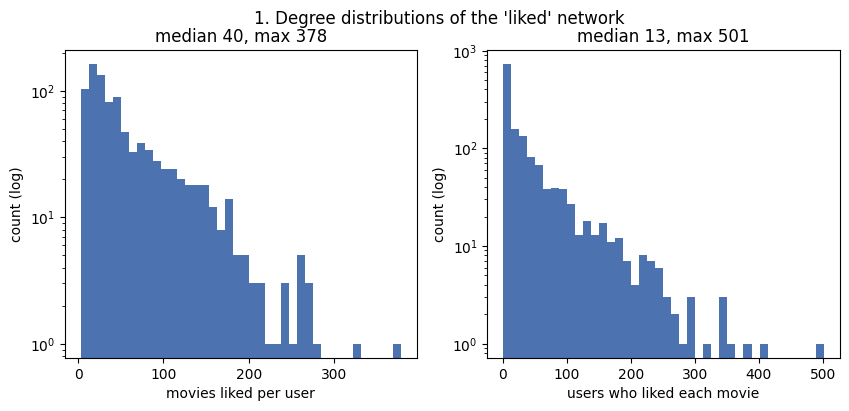

In [24]:
print("\nGRAPHS")
plot_degrees(A, a.outdir)
plt.savefig(os.path.join(a.outdir, "degree_distro.png"), dpi=150, bbox_inches="tight")
plt.show()

#### Degree Distributions Takeawys

##### Users: median 40 liked movies, max 378.
##### Movies: median 13 likes, max 501.
##### Both are heavy-tailed. Most users and movies are low-degree, and a few hubs dominate. The y-axis is log scale, so the tail looks gentler than it is.
##### Roughly 700 movies have only a handful of likes, which is a long tail of obscure titles.
##### Hubs inflate the shared-neighbor weights in the projections. That explains the near-complete projection and why the island method keeps finding one dense core.

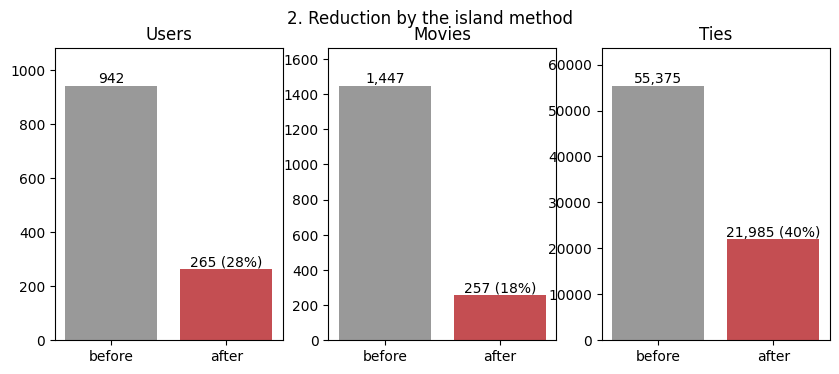

In [25]:
plot_reduction((A.shape[0], A.shape[1], A.nnz), (len(u_keep), len(m_keep), sub.nnz), a.outdir)
plt.savefig(os.path.join(a.outdir, "reduction_by_island.png"), dpi=150, bbox_inches="tight")

####  Reduction
##### This is a success as data reduction and a limited one as structure discovery. It cuts the network by more than 70% while keeping 40% of the ties, but what remains is a dense popularity core.

In [26]:
print("user islands:", sorted(len(g) for g in U_isl))
print("movie islands:", sorted(len(g) for g in M_isl))

user islands: [265]
movie islands: [257]


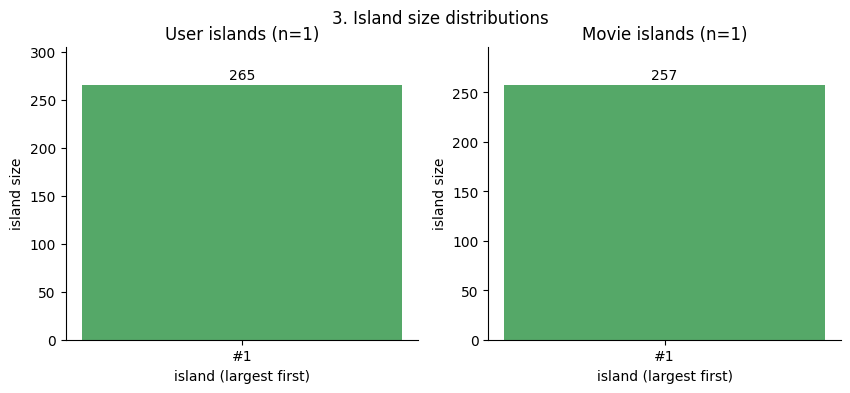

In [27]:
plot_island_sizes(U_isl, M_isl, a.outdir)
plt.savefig(os.path.join(a.outdir, "island_size.png"), dpi=150, bbox_inches="tight")

#### Island Sizes
##### The island is a set of popular mid-90s films. Only 20 of 942 users like half of them, which shows the audience is diffuse, not a cohesive fan group.

#### Two single bars, 265 and 257, confirm the one-island result. 
##### The adaptive code correctly switched to the “few islands” bar layout. The plot carries no distributional information with only one island.


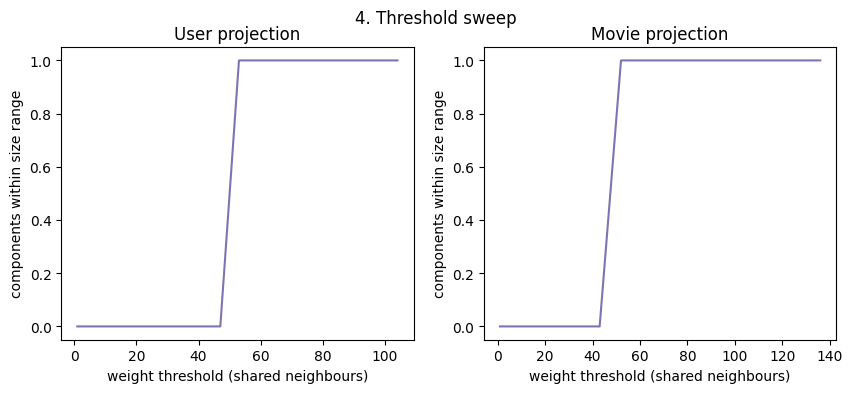

In [28]:
plot_sweep(sw_u, sw_m, a.outdir)
plt.savefig(os.path.join(a.outdir, "threshold_sweep.png"), dpi=150, bbox_inches="tight")

#### Threshold Sweep
##### The count is 0 below a threshold of about 50 (users) or about 45 to 50 (movies), then jumps to 1 and stays flat. Below that threshold the giant component has more than 300 nodes, so none qualifies. Above it, the core shrinks into range and never fragments into several in-range pieces. 
##### A healthy sweep would show multiple components appearing and disappearing, so this flat line confirms the graph is one hub-dominated core. It also means I need about 50 shared liked movies to separate this core, and the median user only likes 40. So the island is made of heavy raters.

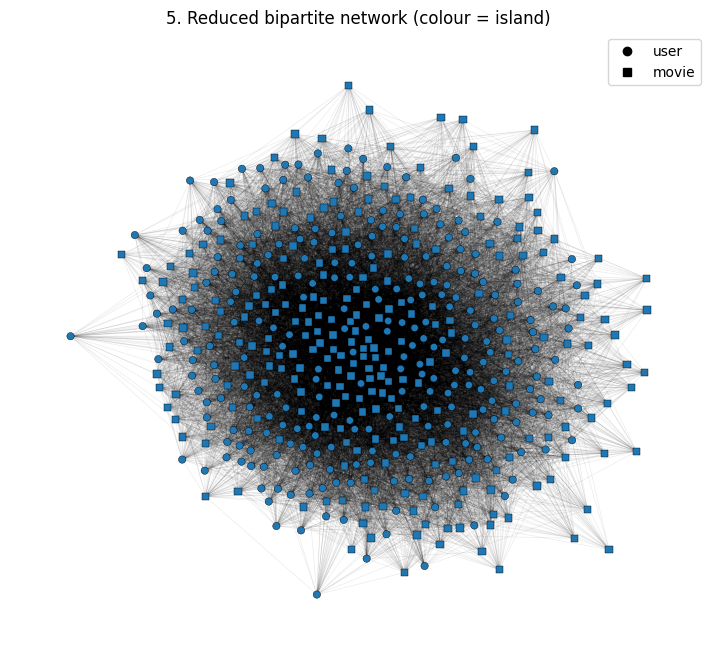

In [29]:
m_lab = {m_keep.index(m): i for i, g in enumerate(M_isl) for m in g}
u_lab = {u_keep.index(u): i for i, g in enumerate(U_isl) for u in g}
plot_network(sub, u_lab, m_lab, a.outdir)
plt.savefig(os.path.join(a.outdir, "reduced_bipartite_network.png"), dpi=150, bbox_inches="tight")

#### Reduced Network Graph
##### This is a single-color hairball. Everything is one island, so the color encoding does nothing, and the dense center is solid black. It is not informative as drawn. It does visually confirm the 32% density and the lack of any community structure.

### Revising the data used for this analysis.

In [30]:
base = "/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k"
ratings = pd.read_csv(f"{base}/u.data", sep="\t", names=["user", "item", "rating", "ts"])
outdir = "/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/new_results"

In [31]:
def build_A(ratings, min_rating):
    r = ratings[ratings.rating >= min_rating]
    u_codes, users = pd.factorize(r.user)
    i_codes, items = pd.factorize(r.item)
    A = sp.csr_matrix(
        (np.ones(len(r), dtype=np.int32), (u_codes, i_codes)),
        shape=(len(users), len(items)),
    )
    return A, users, items

In [32]:
def project_cosine(A):
    """Edge weight = shared neighbours / sqrt(deg_i * deg_j)."""
    W = (A @ A.T).tocsr().astype(float)
    W.setdiag(0)
    W.eliminate_zeros()
    d = np.asarray(A.sum(axis=1)).ravel()
    W = sp.diags(1 / np.sqrt(d)) @ W @ sp.diags(1 / np.sqrt(d))
    return W.tocsr()

In [33]:
def find_islands3(W, min_size, max_size, nested=True, n_thresh=400):
    W = W.tocsr()
    ts = np.unique(np.quantile(W.data, np.linspace(0, 0.9999, n_thresh)))
    kept, seen = [], set()
    for t in ts:
        M = W.copy()
        M.data[M.data < t] = 0
        M.eliminate_zeros()
        _, lab = connected_components(M, directed=False)
        sizes = np.bincount(lab)
        for c in np.where((sizes >= min_size) & (sizes <= max_size))[0]:
            members = frozenset(np.where(lab == c)[0].tolist())
            if members in seen:
                continue
            if nested or not any(members <= k for k in kept):
                seen.add(members)
                kept.append(members)
    return kept

In [34]:
def run(min_deg_user=1, min_deg_movie=1, mn=3, mx=30, mr=4):
    A, users, items = build_A(ratings, mr)
    udeg = np.asarray(A.sum(axis=1)).ravel()
    mdeg = np.asarray(A.sum(axis=0)).ravel()
    um, mm = udeg >= min_deg_user, mdeg >= min_deg_movie
    A2, users2, items2 = A[um][:, mm].tocsr(), users[um], items[mm]
    U = find_islands3(project_cosine(A2), mn, mx, nested=False)
    M = find_islands3(project_cosine(A2.T.tocsr()), mn, mx, nested=False)
    return A2, users2, items2, U, M

In [35]:
# 3) Profile islands for a chosen filter
def profile(du=20, dm=20, top=5):
    A2, u2, i2, U, M = run(du, dm)
    overall = np.asarray(A2.mean(axis=0)).ravel()
    print("USER ISLANDS (movies liked far more than average)")
    for k, isl in enumerate(sorted(U, key=len, reverse=True)):
        rate = np.asarray(A2[list(isl)].mean(axis=0)).ravel()
        best = np.argsort(rate - overall)[::-1][:top]
        print(f"  island {k} (n={len(isl)}):",
              "; ".join(f"{titles[i2[j]]} [{rate[j]:.2f} vs {overall[j]:.2f}]" for j in best))
    print("MOVIE ISLANDS (audience concentration)")
    AT = A2.T.tocsr()
    for k, isl in enumerate(sorted(M, key=len, reverse=True)):
        sub = A2[:, list(isl)]
        frac = np.asarray(sub.sum(axis=1)).ravel() / len(isl)
        print(f"  island {k} (n={len(isl)}):",
              ", ".join(titles[i2[j]] for j in list(isl)[:5]),
              f"| users liking >=half: {(frac >= 0.5).sum()}")

In [36]:
# (min_size, max_size, min_rating, nested)
settings = [
    (3,  30, 4, False),
    (3,  50, 4, False),
    (3, 150, 4, False),
    (3,  50, 5, False),
    (3,  30, 4, True),
    (3,  50, 4, True),
    (3, 150, 4, True),
    (3,  50, 5, True),
]

In [37]:
rows = []
for mn, mx, mr, nested in [(3,30,4,False),(3,50,4,False),(3,30,4,True),(3,50,4,True)]:
    A, users, items = build_A(ratings, mr)
    U = find_islands3(project_cosine(A), mn, mx, nested)
    M = find_islands3(project_cosine(A.T.tocsr()), mn, mx, nested)
    rows.append({"min": mn, "max": mx, "min_rating": mr,
                 "mode": "nested" if nested else "maximal",
                 "user_islands": len(U), "movie_islands": len(M),
                 "users_covered": len(set().union(*U)) if U else 0,
                 "movies_covered": len(set().union(*M)) if M else 0})
print(pd.DataFrame(rows).to_string(index=False))

 min  max  min_rating    mode  user_islands  movie_islands  users_covered  movies_covered
   3   30           4 maximal            16             43             62             198
   3   50           4 maximal            16             43             62             198
   3   30           4  nested            21             54             62             198
   3   50           4  nested            21             54             62             198


### This table is from the cosine-weighted projection, and it tells a different story from the raw-count table.
##### max_size of 30 vs 50 changes nothing. No component lands between 31 and 50 members. Components are either tiny (3-9) or already huge, so the cap isn’t what’s limiting results. Components jump from tiny to giant as the threshold drops, which is typical of a giant-component transition.
##### Nested mode finds more islands but no new members. Nested adds 5 user and 11 movie islands, but coverage stays the same (62 users, 198 movies). The extras are sub-islands inside islands that maximal mode already found.
##### Coverage is very small. The 62 users are about 6.6% of 942, and the 198 movies are about 14% of 1,447. The method keeps a tiny, very tight core and discards most of the network.

In [38]:
base = "/Users/Audiorunner13/CUNY MSDS Course Work/Data620 Fall 2026/Week 6/Project 2/ml-100k"
titles = pd.read_csv(f"{base}/u.item", sep="|", encoding="latin-1",
                     header=None, usecols=[0, 1], names=["id", "title"]).set_index("id").title

In [39]:
# 1) Artifact check on the unfiltered run
A2, users2, items2, U, M = run()
udeg = np.asarray(A2.sum(axis=1)).ravel()
mdeg = np.asarray(A2.sum(axis=0)).ravel()
print("user islands: sizes", sorted(len(x) for x in U))
print("median liked-count, island users:",
      np.median([udeg[list(x)].mean() for x in U]), "| all users:", np.median(udeg))
print("median likes, island movies:",
      np.median([mdeg[list(x)].mean() for x in M]), "| all movies:", np.median(mdeg))

user islands: sizes [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 7, 9]
median liked-count, island users: 23.0 | all users: 39.5
median likes, island movies: 4.0 | all movies: 13.0


In [40]:
# 2) Degree-filtered comparison table
rows = []
for du, dm in [(1, 1), (10, 10), (20, 20), (30, 30)]:
    A2, u2, i2, U, M = run(du, dm)
    rows.append({"min_user_likes": du, "min_movie_likes": dm,
                 "users": A2.shape[0], "movies": A2.shape[1],
                 "user_islands": len(U), "movie_islands": len(M),
                 "users_covered": len(set().union(*U)) if U else 0,
                 "movies_covered": len(set().union(*M)) if M else 0})
print(pd.DataFrame(rows).to_string(index=False))

 min_user_likes  min_movie_likes  users  movies  user_islands  movie_islands  users_covered  movies_covered
              1                1    942    1447            16             43             62             198
             10               10    897     824            15             24             69             114
             20               20    703     621            15             14             70              65
             30               30    553     514            10             12             62              54


##### The islands survive degree filtering on the user side and partly on the movie side. That supports using the filtered results, and (20, 20) looks like the best setting.
##### Movie islands drop sharply (43 → 14 at 20/20). Most of the original 43 were low-popularity noise, which confirms the artifact.
##### User islands are stable at 15-16 until the 30/30 filter, which starts to erode them.
##### 20/20 is a sensible choice. It keeps the most users covered (70), removes most of the artifact, and still retains 703 users and 621 movies.

In [41]:
profile(20, 20)

USER ISLANDS (movies liked far more than average)
  island 0 (n=12): Secrets & Lies (1996) [0.92 vs 0.18]; Postino, Il (1994) [0.83 vs 0.17]; Lone Star (1996) [0.83 vs 0.18]; Antonia's Line (1995) [0.67 vs 0.06]; Breaking the Waves (1996) [0.58 vs 0.07]
  island 1 (n=8): Natural Born Killers (1994) [1.00 vs 0.07]; Shining, The (1980) [1.00 vs 0.19]; Nightmare on Elm Street, A (1984) [0.88 vs 0.07]; American Werewolf in London, An (1981) [0.88 vs 0.07]; Evil Dead II (1987) [0.75 vs 0.07]
  island 2 (n=7): Edge, The (1997) [0.86 vs 0.07]; Murder at 1600 (1997) [0.86 vs 0.09]; Amistad (1997) [0.86 vs 0.10]; As Good As It Gets (1997) [0.86 vs 0.11]; Devil's Advocate, The (1997) [0.86 vs 0.12]
  island 3 (n=6): Speed (1994) [1.00 vs 0.20]; Alien 3 (1992) [0.83 vs 0.04]; Under Siege (1992) [0.83 vs 0.08]; Aliens (1986) [1.00 vs 0.30]; Terminator, The (1984) [1.00 vs 0.30]
  island 4 (n=4): Like Water For Chocolate (Como agua para chocolate) (1992) [1.00 vs 0.14]; Four Weddings and a Funeral 

#### profile(20, 20) 
##### Re-runs the island search on the degree-filtered network and prints a short description of every island, so you can see what each group actually is. The two numbers are the minimum likes per user and per movie (du=20, dm=20).

In [42]:
 DU, DM = 20, 20                      # <- your chosen filter
A2, u2, i2, U, M = run(DU, DM)
U = sorted(U, key=len, reverse=True)
M = sorted(M, key=len, reverse=True)

In [43]:
print("\nGRAPHS")


GRAPHS


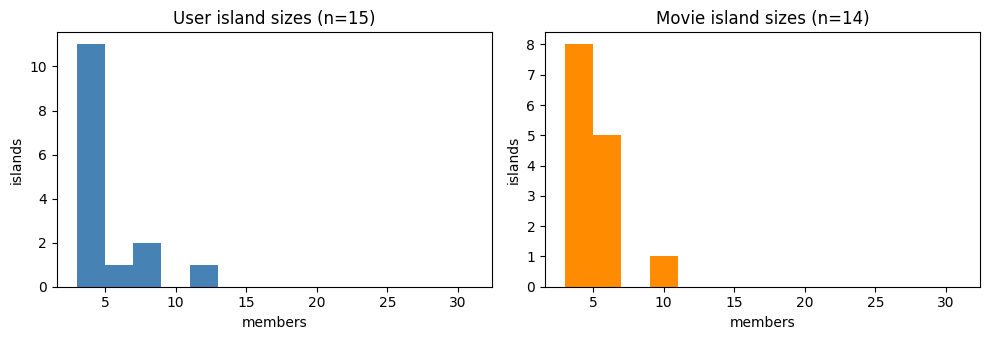

In [44]:
# 1) Island size distributions
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist([len(x) for x in U], bins=range(3, 32, 2), color="steelblue")
ax[0].set_title(f"User island sizes (n={len(U)})")
ax[1].hist([len(x) for x in M], bins=range(3, 32, 2), color="darkorange")
ax[1].set_title(f"Movie island sizes (n={len(M)})")
for a_ in ax: a_.set_xlabel("members"); a_.set_ylabel("islands")
plt.tight_layout(); 
plt.savefig(os.path.join(a.outdir, "island_size_distro.png"), dpi=150, bbox_inches="tight")

##### Users (n=15): 11 of 15 islands have 3-4 members, and the largest has about 12.
##### Movies (n=14): 8 islands have 3-5 members, and one has 10.
##### Sizes are heavily right-skewed with nothing near the cap of 30. This explains why raising max_size from 30 to 50 changed nothing.
##### Small islands are expected here because the method keeps only the tightest cosine cores. The risk is that a 3-person island can look coherent by chance, so only the larger ones should carry interpretive weight.

In [45]:
# 2) Reduced bipartite network, colored by island
u_island = {u: k for k, isl in enumerate(U) for u in isl}
m_island = {m: k for k, isl in enumerate(M) for m in isl}
keep_u, keep_m = sorted(u_island), sorted(m_island)

sub = A2[keep_u][:, keep_m].tocoo()
G = nx.Graph()
G.add_nodes_from([("u", u) for u in keep_u], bipartite=0)
G.add_nodes_from([("m", m) for m in keep_m], bipartite=1)
G.add_edges_from((("u", keep_u[r]), ("m", keep_m[c])) for r, c in zip(sub.row, sub.col))

print(f"Bipartite network: {A.shape[0]:,} users, {A.shape[1]:,} movies, {A.nnz:,} ties")

Bipartite network: 942 users, 1,447 movies, 55,375 ties


In [46]:
cmap = plt.get_cmap("tab20")
colors = [cmap(u_island[n[1]] % 20) if n[0] == "u" else cmap(m_island[n[1]] % 20) for n in G]
shapes_u = [n for n in G if n[0] == "u"]
shapes_m = [n for n in G if n[0] == "m"]

In [47]:
sub = A2[keep_u][:, keep_m].tocoo()
G = nx.Graph()
G.add_nodes_from([("u", u) for u in keep_u], bipartite=0)
G.add_nodes_from([("m", m) for m in keep_m], bipartite=1)
G.add_edges_from((("u", keep_u[r]), ("m", keep_m[c])) for r, c in zip(sub.row, sub.col))

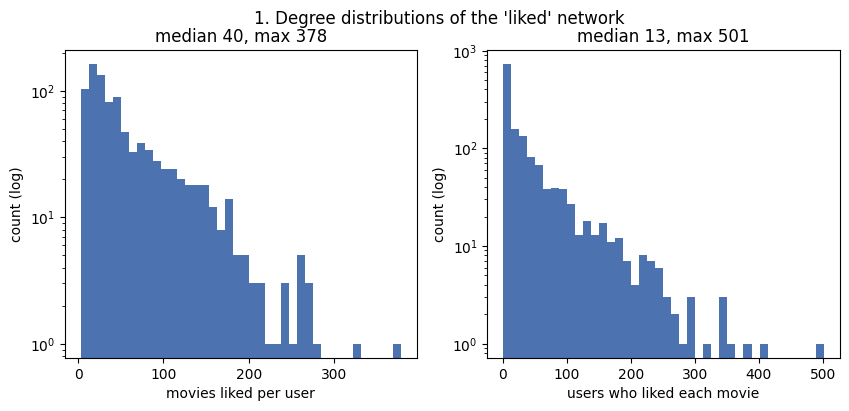

In [48]:
plot_degrees(A, outdir)
plt.savefig(os.path.join(a.outdir, "degree_distro_2.png"), dpi=150, bbox_inches="tight")

##### Both distributions are heavy-tailed on a log y-axis.
##### Users: median 40 likes, max 378. Most users like few movies, and a few like hundreds.
##### Movies: median 13, max 501. There is a large spike at the lowest bins, so hundreds of movies have almost no likes.
##### This supports the degree-filter decision. The many low-degree movies are the ones that form spurious cosine islands, and the hub users and movies are the ones that can never reach high cosine.

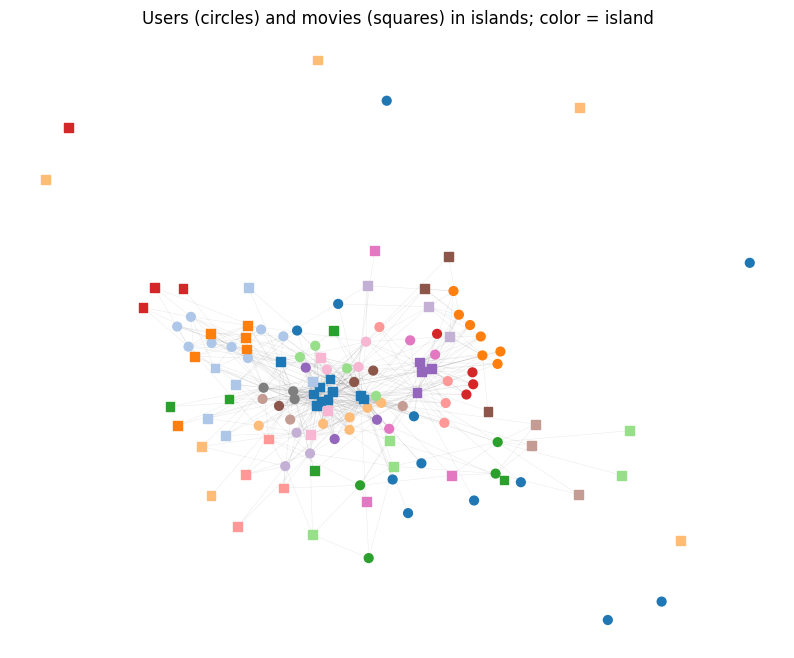

In [49]:
pos = nx.spring_layout(G, seed=1, k=0.25)
plt.figure(figsize=(10, 8))
nx.draw_networkx_edges(G, pos, alpha=0.08, width=0.4)
nx.draw_networkx_nodes(G, pos, nodelist=shapes_u, node_shape="o", node_size=40,
                       node_color=[cmap(u_island[n[1]] % 20) for n in shapes_u])
nx.draw_networkx_nodes(G, pos, nodelist=shapes_m, node_shape="s", node_size=40,
                       node_color=[cmap(m_island[n[1]] % 20) for n in shapes_m])
plt.title("Users (circles) and movies (squares) in islands; color = island")
plt.axis("off"); 
plt.savefig(os.path.join(a.outdir, "island_network_graph.png"), dpi=150, bbox_inches="tight")

##### Circles are users, squares are movies, and color is island membership.
##### Edges are faint, and the layout shows a dense central hub with island members mixed together, plus peripheral nodes far from it.
##### Several island nodes appear nearly isolated (for example, the blue circles at the edges and the squares in the corners). A spring layout pushes these outward because, in this subgraph, they have few or no ties to other kept nodes.
##### Colors cycle through 20 values, so the legend is not unique. Islands 0 and 20, for instance, would share a color. 
##### This tells you islands are internally cohesive within each projection (users with users, movies with movies), but the cross-links between a user island and a movie island are thin. A tight cluster of movies does not necessarily map onto a tight cluster of users, which is expected because islands were found separately on each side.

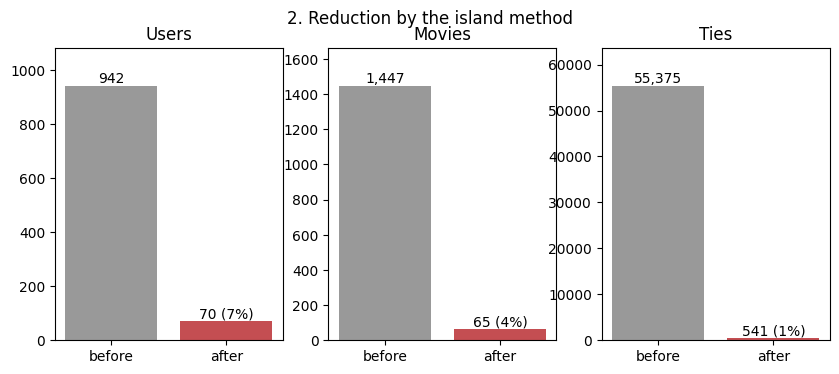

In [50]:
plot_reduction((A.shape[0], A.shape[1], A.nnz), (len(keep_u), len(keep_m), sub.nnz), outdir)
plt.savefig(os.path.join(a.outdir, "reductionby_island_2.png"), dpi=150, bbox_inches="tight")

##### Users 942 → 70 (7%), movies 1,447 → 65 (4%), ties 55,375 → 541 (1%).
##### Ties shrink much faster than nodes, so the retained nodes are much sparser relative to each other than the full network. Island members account for only 1% of all liked-ties, so the reduced graph is a small, distinctive sample rather than a faithful compression of the data.

In [51]:
print("user islands:", sorted(len(g) for g in U))
print("movie islands:", sorted(len(g) for g in U))

user islands: [3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 6, 7, 8, 12]
movie islands: [3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 6, 7, 8, 12]


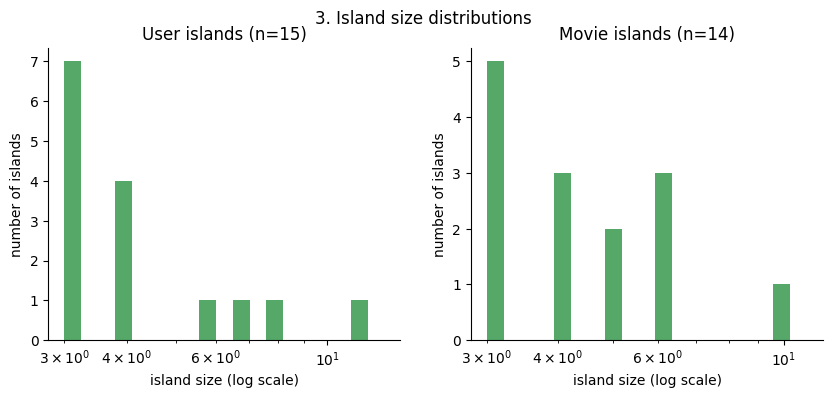

In [58]:
plot_island_sizes(U, M, outdir)
plt.savefig(os.path.join(a.outdir, "island_size_distro.png"), dpi=150, bbox_inches="tight")

##### Same message as Figure 1 on a log x-axis: 7 user islands of size 3, 4 of size 4, then single islands at about 6, 7, 8 and 12.
##### Movie islands are spread slightly more evenly (5, 3, 2, 3, then one of 10). Movie islands are spread slightly more evenly (5, 3, 2, 3, then one of 10).
##### The tail is thin, so there are no mid-sized communities (13-30), only small cores and, above that, the giant component.

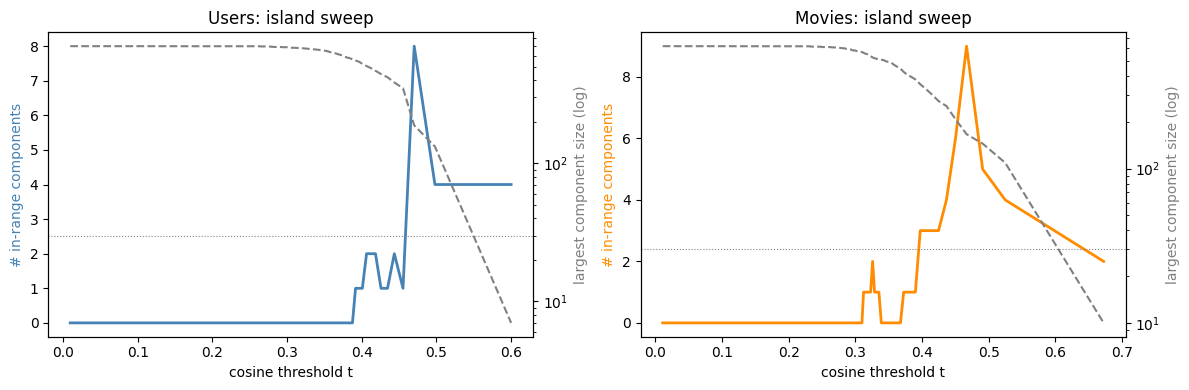

In [59]:
DU, DM = 20, 20          # same degree filter you chose for the islands
MN, MX = 3, 30

A2, u2, i2, U, M = run(DU, DM)
sw_u = island_sweep(project_cosine(A2), MN, MX)
sw_m = island_sweep(project_cosine(A2.T.tocsr()), MN, MX)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, sw, name, color in [(axes[0], sw_u, "Users", "steelblue"),
                            (axes[1], sw_m, "Movies", "darkorange")]:
    ax.plot(sw.threshold, sw.in_range, color=color, lw=2, label=f"# components, size {MN}-{MX}")
    ax.set_xlabel("cosine threshold t")
    ax.set_ylabel("# in-range components", color=color)
    ax.set_title(f"{name}: island sweep")

    ax2 = ax.twinx()
    ax2.plot(sw.threshold, sw.largest, color="gray", ls="--", label="largest component")
    ax2.set_yscale("log")
    ax2.set_ylabel("largest component size (log)", color="gray")
    ax2.axhline(MX, color="gray", ls=":", lw=0.8)   # max_size cap

plt.tight_layout()
plt.savefig(os.path.join(a.outdir, "island_sweep.png"), dpi=150, bbox_inches="tight")
plt.show()

##### The gray dashed line is the largest component size (log scale). It stays near the full network (several hundred nodes) until the cosine threshold reaches about 0.35-0.4, then falls steeply. This is a classic percolation transition.
##### The colored line counts components within the 3-30 size range.
##### Users: zero in-range components below t ≈ 0.39, then a sharp peak of 8 around t ≈ 0.47, settling to a plateau of 4 from t ≈ 0.5 up.
##### Movies: zero until t ≈ 0.31, a peak of 9 near t ≈ 0.47, then a decline to 2 by t ≈ 0.67.
##### Islands only exist in a narrow window, roughly t = 0.4 to 0.5, right where the giant component breaks apart. Below it everything is one blob, and above it components dissolve or fall below size 3.
##### The peak is sharp, so the island count is sensitive to the threshold grid. Using 400 quantile-based thresholds (n_thresh=400) helps, since thresholds are densest where edge weights are dense.

### In Conclusion
##### The data is MovieLens 100k: about 100,000 movie ratings from 942 people on roughly 1,600 movies. The goal was to find “islands”, small groups of people who like the same movies, and small groups of movies liked by the same people. Think of a handful of friends who all love horror films, or a handful of movies that tend to appeal to the same crowd.
#### What was found
##### Allowing islands up to 30 members or up to 50 made no difference, because real islands were small, mostly 3-12 members.
##### An early check showed a problem. The first islands were dominated by people who’d rated very few movies and by movies with very few fans. With so little data, two such people can look nearly identical by luck. This is a measurement artifact, not a real shared taste.
##### The fix was to require people and movies to have at least 20 likes. This cut the movie islands from 43 to 14, which confirms most of the early ones were noise, while the user islands stayed stable at about 15.
#### The final result: 15 groups of users and 14 groups of movies.
##### The groups make sense. There was a horror-lovers group, an art-house and foreign-film group, a classic-Hollywood group, a family and animation group, an action and sci-fi group, and the three Three Colors films appearing together.
##### Some groups mostly reflect when people were watching. Several are simply 1997 releases, so they may capture timing more than taste.
##### Some groups appeal to almost everyone, such as one group of Star Wars-type blockbusters that most users liked, while others are very narrow, with only 11 or 16 fans.
#### What it means, and what to be careful about
##### The islands are small and rare. They cover only about 7% of users, 4% of movies, and 1% of all the likes. They show distinctive pockets of taste, not a sorting of everyone into categories.
##### Islands only appear in a narrow window. When the similarity bar is too low, everything is one blob. When it’s too high, groups shrink below 3 members. The sweet spot is a fairly narrow range.
##### Small groups are shaky. In a group of three people, “all three liked it” is a thin basis for a conclusion. The larger groups (7-12 members) are more trustworthy.
##### Most people and movies have few likes. The typical person liked about 40 movies and the typical movie about 13 fans, with a few outliers at the extreme. That unevenness is why the filtering step mattered.
#### Finally, the method works. 
##### After filtering out thinly rated people and movies, it finds understandable groups of like-minded viewers and similar movies. The result is a small, clean sample of the clearest taste clusters rather than a map of everyone.